<a href="https://colab.research.google.com/github/Datso653/Laboratorio-de-metodos-Cuantitativos-Aplicados-a-la-gestion/blob/main/notebooks/15_Clase_de_an%C3%A1lisis_de_procesos_organizacionales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Procesos Organizacionales y la PyME

## Laboratorio de Métodos Cuantitativos
###De las métricas financieras al control de gestión

**Objetivos:**
1. Entender procesos organizacionales en el contexto PyME (Order-to-Cash y Procure-to-Pay).
2. Medir KPIs de proceso con pandas.
3. Vincular KPIs con métricas financieras (WACC, ROA, tasa efectiva).
4. **Construir un control de cash flow con visualizaciones.**
5. **Simular escenarios de tensión de caja y detectar umbrales.**
6. **Interpretar un semáforo de salud financiera.**

**Pregunta que guía la clase:**
> ¿Puede una PyME ser rentable y fundirse igual? ¿Cómo lo detectamos antes de que pase?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (11, 5)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

## 1. Del resultado financiero al proceso en una PyME

| Métrica | En la PyME se traduce como... |
|---------|-------------------------------|
| WACC | Tasa del préstamo + costo de oportunidad del dueño |
| ROA | Rendimiento sobre mercadería + local + equipos |
| VAN | ¿Conviene invertir en esa máquina / ese local? |
| TIR | ¿Qué rinde el negocio vs. un plazo fijo? |
| Tasa efectiva | La del descuento por pronto pago del proveedor |

**Pero hay algo más importante que el resultado: la CAJA.**

> Una PyME puede tener VAN positivo y fundirse igual por un desfase de caja.

**Los dos procesos críticos de una PyME comercial:**
- **Order-to-Cash (O2C):** pedido → cobro.
- **Procure-to-Pay (P2P):** compra → pago.

** Se deben considerar 4 dimensiones de todo proceso:** tiempo, costo, calidad, volumen.

---
##CASO 1: Order-to-Cash de una PyME comercial

**Contexto:** "Distribuidora del Sur" vende insumos a comercios minoristas. El dueño maneja todo desde un Excel.

**Etapas:** Pedido → Aprobación de crédito → Preparación → Despacho → Facturación → Cobro.

In [2]:
np.random.seed(42)
n = 500

etapas_otc = ['Pedido', 'Aprobación crédito', 'Preparación',
              'Despacho', 'Facturación', 'Cobro']

df_otc = pd.DataFrame({
    'id_pedido': range(1000, 1000 + n),
    'fecha_pedido': pd.date_range('2025-01-01', periods=n, freq='D')[:n],
    'etapa': np.random.choice(etapas_otc, n),
    'dias_etapa': np.random.gamma(shape=2, scale=2, size=n).round(1),
    'costo_transaccion': np.random.normal(800, 200, n).round(2),
    'monto_venta': np.random.normal(25000, 8000, n).round(2),
    'retrabajos': np.random.poisson(0.3, n),
    'satisfaccion': np.random.choice([1,2,3,4,5], n, p=[0.05,0.1,0.25,0.35,0.25])
})

# Cuello de botella: el dueño firma toda aprobación de crédito a mano
mask = df_otc['etapa'] == 'Aprobación crédito'
df_otc.loc[mask, 'dias_etapa'] *= 3.0
df_otc.loc[mask, 'retrabajos'] += 1

df_otc

,id_pedido,fecha_pedido,etapa,dias_etapa,costo_transaccion,monto_venta,retrabajos,satisfaccion
0,1000,2025-01-01,Despacho,2.70,"1,001.96","20,874.26",0,1
1,1001,2025-01-02,Facturación,1.00,350.18,"27,383.86",0,4
2,1002,2025-01-03,Preparación,2.30,663.40,"31,087.24",0,3
3,1003,2025-01-04,Facturación,3.70,811.83,"23,403.77",1,5
4,1004,2025-01-05,Facturación,7.30,"1,025.22","15,694.48",0,5
...,...,...,...,...,...,...,...,...
495,1495,2026-05-11,Despacho,9.40,966.76,"28,146.15",0,3
496,1496,2026-05-12,Aprobación crédito,4.80,714.45,"36,303.96",1,5
497,1497,2026-05-13,Aprobación crédito,5.70,746.89,"27,605.66",1,5
498,1498,2026-05-14,Facturación,1.00,896.69,"22,043.32",1,5


In [3]:
df_otc.describe()


,id_pedido,fecha_pedido,dias_etapa,costo_transaccion,monto_venta,retrabajos,satisfaccion
count,500.00,500,500.00,500.00,500.00,500.00,500.00
mean,"1,249.50",2025-09-07 12:00:00,5.40,796.99,"24,784.63",0.42,3.67
min,"1,000.00",2025-01-01 00:00:00,0.20,222.35,"2,339.84",0.00,1.00
25%,"1,124.75",2025-05-05 18:00:00,2.20,659.02,"19,413.16",0.00,3.00
50%,"1,249.50",2025-09-07 12:00:00,3.90,799.63,"24,871.89",0.00,4.00
75%,"1,374.25",2026-01-10 06:00:00,6.93,922.25,"30,345.21",1.00,5.00
max,"1,499.00",2026-05-15 00:00:00,46.20,"1,332.64","46,846.94",4.00,5.00
std,144.48,NaN,4.92,195.11,"8,018.25",0.63,1.10


In [4]:
df_otc['etapa'].value_counts()

,count
etapa,
Despacho,97
Pedido,90
Cobro,86
Preparación,77
Facturación,75
Aprobación crédito,75


In [5]:
resumen_otc = df_otc.groupby('etapa').agg(
    pedidos=('id_pedido', 'count'),
    lead_time_prom=('dias_etapa', 'mean'),
    lead_time_p90=('dias_etapa', lambda x: x.quantile(0.90)),
    costo_prom=('costo_transaccion', 'mean'),
    retrabajos_prom=('retrabajos', 'mean'),
    satisfaccion=('satisfaccion', 'mean')
).round(2).sort_values('lead_time_prom', ascending=False)

resumen_otc

,pedidos,lead_time_prom,lead_time_p90,costo_prom,retrabajos_prom,satisfaccion
etapa,,,,,,
Aprobación crédito,75,12.23,20.70,760.54,1.28,3.80
Cobro,86,4.78,9.30,798.19,0.30,3.58
Despacho,97,4.36,9.34,816.54,0.21,3.54
Facturación,75,4.02,7.88,801.25,0.27,3.73
Preparación,77,3.90,7.70,785.12,0.19,3.77
Pedido,90,3.84,7.43,811.76,0.39,3.66


/tmp/ipykernel_2944/3868276564.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_otc, x='etapa', y='dias_etapa', estimator=np.mean,


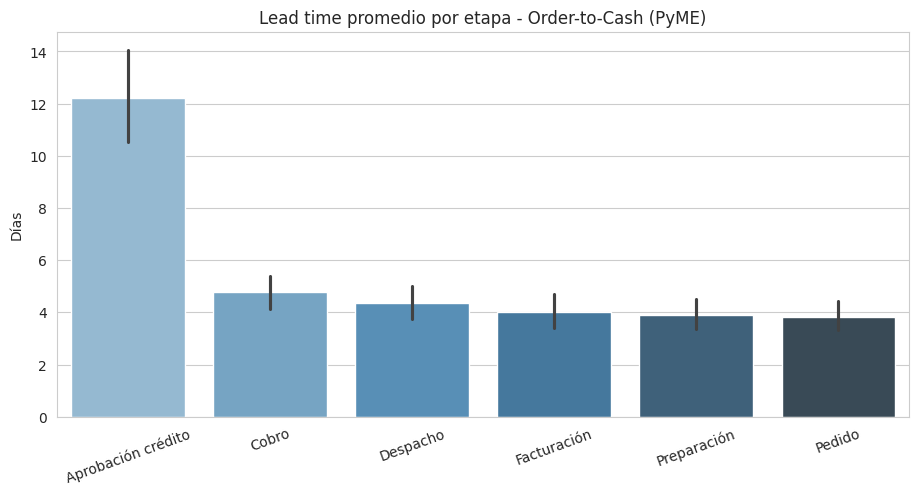

In [6]:
plt.figure(figsize=(11,5))
sns.barplot(data=df_otc, x='etapa', y='dias_etapa', estimator=np.mean,
            order=resumen_otc.index, palette='Blues_d')
plt.title('Lead time promedio por etapa - Order-to-Cash (PyME)')
plt.ylabel('Días')
plt.xlabel('')
plt.xticks(rotation=20)
plt.show()

**Para pensar:**
1. ¿Qué etapa concentra el mayor lead time?
2. ¿Coincide con la etapa de mayor retrabajo?
3. ¿Qué implicancias tiene para la PyME? Pensá en el dueño firmando todo.

---
##CASO 2: Procure-to-Pay de la misma PyME

**Contexto:** Muchos proveedores ofrecen **2/10 net 30** (2% de descuento si paga en 10 días, o paga a 30).

**Etapas:** Solicitud → Aprobación → Orden de compra → Recepción → Factura → Pago.

In [7]:
np.random.seed(7)
n_p2p = 400

etapas_p2p = ['Solicitud', 'Aprobación', 'Orden de compra',
              'Recepción', 'Factura', 'Pago']

df_p2p = pd.DataFrame({
    'id_compra': range(5000, 5000 + n_p2p),
    'fecha_solicitud': pd.date_range('2025-01-01', periods=n_p2p, freq='D')[:n_p2p],
    'etapa': np.random.choice(etapas_p2p, n_p2p),
    'dias_etapa': np.random.gamma(shape=2, scale=2, size=n_p2p).round(1),
    'monto_compra': np.random.normal(18000, 5000, n_p2p).round(2),
    'costo_admin': np.random.normal(500, 150, n_p2p).round(2),
    'errores_documento': np.random.poisson(0.5, n_p2p),
    'proveedor': np.random.choice(['A','B','C','D','E'], n_p2p)
})

mask_ap = df_p2p['etapa'] == 'Aprobación'
df_p2p.loc[mask_ap, 'dias_etapa'] *= 3.0
df_p2p.loc[mask_ap, 'errores_documento'] += 1

mask_pg = df_p2p['etapa'] == 'Pago'
df_p2p.loc[mask_pg, 'dias_etapa'] *= 2.0

df_p2p

,id_compra,fecha_solicitud,etapa,dias_etapa,monto_compra,costo_admin,errores_documento,proveedor
0,5000,2025-01-01,Factura,4.20,"20,272.52",498.92,0,E
1,5001,2025-01-02,Aprobación,17.70,"17,404.73",448.87,1,E
2,5002,2025-01-03,Recepción,1.20,"9,281.16",346.43,0,C
3,5003,2025-01-04,Recepción,2.60,"17,353.89",662.35,0,B
4,5004,2025-01-05,Factura,4.70,"27,009.89",422.76,0,C
...,...,...,...,...,...,...,...,...
395,5395,2026-01-31,Pago,13.60,"21,153.40",529.72,0,D
396,5396,2026-02-01,Aprobación,6.00,"20,248.14",603.32,1,C
397,5397,2026-02-02,Aprobación,10.20,"20,898.29",504.54,1,A
398,5398,2026-02-03,Aprobación,20.70,"23,106.58",453.68,1,C


In [8]:
resumen_p2p = df_p2p.groupby('etapa').agg(
    compras=('id_compra', 'count'),
    lead_time_prom=('dias_etapa', 'mean'),
    lead_time_p90=('dias_etapa', lambda x: x.quantile(0.90)),
    costo_admin_prom=('costo_admin', 'mean'),
    errores_prom=('errores_documento', 'mean')
).round(2).sort_values('lead_time_prom', ascending=False)

resumen_p2p

,compras,lead_time_prom,lead_time_p90,costo_admin_prom,errores_prom
etapa,,,,,
Aprobación,66,11.26,20.70,504.50,1.52
Pago,68,7.67,15.10,488.11,0.53
Orden de compra,57,4.44,9.02,534.51,0.44
Factura,74,3.98,7.28,492.10,0.42
Solicitud,66,3.65,6.95,449.28,0.45
Recepción,69,3.54,6.24,493.43,0.46


/tmp/ipykernel_2944/2022936073.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_p2p, x='etapa', y='dias_etapa', estimator=np.mean,


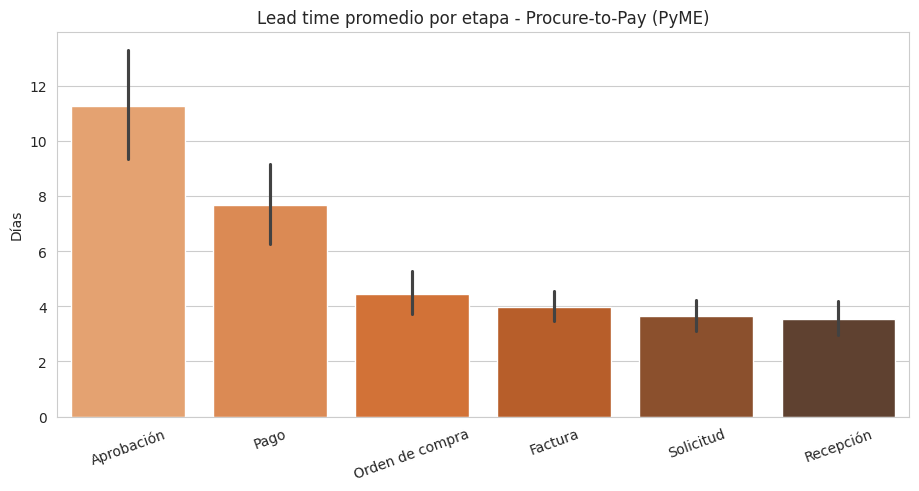

In [9]:
plt.figure(figsize=(11,5))
sns.barplot(data=df_p2p, x='etapa', y='dias_etapa', estimator=np.mean,
            order=resumen_p2p.index, palette='Oranges_d')
plt.title('Lead time promedio por etapa - Procure-to-Pay (PyME)')
plt.ylabel('Días')
plt.xlabel('')
plt.xticks(rotation=20)
plt.show()

In [14]:
# Descuento 2/10 net 30 -> TEA implícita
d = 0.02
dias_desc = 10
dias_neto = 30

tea_descuento = (1 + d/(1-d))**(365/(dias_neto - dias_desc)) - 1
wacc_pyme = 0.45   # en PyME argentina, el costo de capital suele ser altísimo

print(f"TEA implícita del descuento: {tea_descuento:.2%}")
print(f"WACC PyME estimado: {wacc_pyme:.2%}")
print(f"¿Conviene tomar el descuento? {'SÍ' if tea_descuento > wacc_pyme else 'NO'}")

TEA implícita del descuento: 44.59%
WACC PyME estimado: 45.00%
¿Conviene tomar el descuento? NO


**Para pensar:**
1. ¿Qué etapa del P2P tiene el mayor lead time?
2. Con un WACC PyME del 45%, ¿conviene tomar el descuento del proveedor?
3. ¿Qué pasaría con la caja si pagara a 10 días en lugar de 30?

---
##Cash Flow PyME

**Principios de calibración:**

1. **Cobranzas ≈ ventas del período** con desfase por mora, no pérdida estructural.
2. **Pagos a proveedores alineados al CMV** (55–65% de ventas), no al 100%.
3. **Estacionalidad argentina**: enero–febrero flojos, diciembre fuerte.
4. **Caja inicial**: una PyME sana arranca con ~1.5 meses de egresos.
5. **Saldos negativos puntuales**, no crónicos.

> Un flujo con saldos negativos todos los meses no es una PyME: es una empresa en liquidación. Un modelo útil muestra tensión, no catástrofe.

In [15]:
np.random.seed(2024)
meses = pd.date_range('2025-01-01', periods=12, freq='MS')

# Estacionalidad típica (índice mensual)
estacionalidad = np.array([0.75, 0.80, 0.95, 1.00, 1.05, 1.10,
                            0.95, 0.90, 1.00, 1.05, 1.10, 1.35])
ventas_base = 3_800_000
ventas = ventas_base * estacionalidad * np.random.uniform(0.95, 1.05, 12)

# Cobranzas: ~98% de ventas en promedio, con variabilidad por mora
cobranzas = ventas * np.random.uniform(0.92, 1.05, 12)
cobranzas[0] *= 1.15  # enero cobra deuda de diciembre
cobranzas[1] *= 1.08

# Compras = ~60% de ventas (CMV típico de distribuidora)
compras = ventas * np.random.uniform(0.55, 0.65, 12)
pagos_proveedores = compras * np.random.uniform(0.80, 0.95, 12)

# Costos fijos
sueldos = np.full(12, 900_000)
alquiler = np.full(12, 350_000)
servicios = np.random.normal(180_000, 25_000, 12)
impuestos = ventas * 0.08

df_cf = pd.DataFrame({
    'mes': meses,
    'ventas': ventas,
    'cobranzas': cobranzas,
    'pagos_proveedores': pagos_proveedores,
    'sueldos': sueldos,
    'alquiler': alquiler,
    'servicios': servicios,
    'impuestos': impuestos
})

df_cf['ingresos'] = df_cf['cobranzas']
df_cf['egresos'] = (df_cf['pagos_proveedores'] + df_cf['sueldos']
                    + df_cf['alquiler'] + df_cf['servicios'] + df_cf['impuestos'])
df_cf['saldo_mes'] = df_cf['ingresos'] - df_cf['egresos']

# Caja inicial: 1.5 meses de egresos
caja_inicial = df_cf['egresos'].mean() * 1.5
df_cf['saldo_acumulado'] = caja_inicial + df_cf['saldo_mes'].cumsum()

print(f"Caja inicial: ${caja_inicial:,.0f}")
df_cf[['mes','ingresos','egresos','saldo_mes','saldo_acumulado']].round(0)

Caja inicial: $5,582,480


,mes,ingresos,egresos,saldo_mes,saldo_acumulado
0,2025-01-01,"3,300,787.00","3,200,333.00","100,453.00","5,682,933.00"
1,2025-02-01,"3,499,361.00","3,444,276.00","55,086.00","5,738,019.00"
2,2025-03-01,"3,519,694.00","3,610,847.00","-91,153.00","5,646,866.00"
3,2025-04-01,"3,622,520.00","3,539,662.00","82,858.00","5,729,724.00"
4,2025-05-01,"3,788,621.00","3,725,919.00","62,702.00","5,792,426.00"
5,2025-06-01,"3,811,741.00","3,664,704.00","147,037.00","5,939,463.00"
6,2025-07-01,"3,718,331.00","3,592,418.00","125,913.00","6,065,376.00"
7,2025-08-01,"3,535,837.00","3,692,339.00","-156,502.00","5,908,874.00"
8,2025-09-01,"3,613,973.00","3,755,083.00","-141,110.00","5,767,764.00"
9,2025-10-01,"3,701,122.00","3,707,682.00","-6,561.00","5,761,203.00"


###KPIs de caja

- **DSO (Days Sales Outstanding):** días promedio en cobrar. → O2C.
- **DPO (Days Payable Outstanding):** días promedio en pagar. → P2P.
- **CCC (Cash Conversion Cycle):** `CCC = DSO - DPO`. Días que la plata está en la calle.

In [24]:
dso = df_otc[df_otc['etapa']=='Cobro']['dias_etapa'].mean() + 30
dpo = df_p2p[df_p2p['etapa']=='Pago']['dias_etapa'].mean() + 20
ccc = dso - dpo

print(f"DSO estimado: {dso:.1f} días")
print(f"DPO estimado: {dpo:.1f} días")
print(f"CCC: {ccc:.1f} días")
print(f"\nLa PyME financia {ccc:.0f} días de operación con capital propio o crédito.")

ventas_diarias = df_cf['ingresos'].mean() / 30
caja_necesaria = ventas_diarias * ccc
print(f"\nCaja necesaria para sostener el CCC: ${caja_necesaria:,.0f}")

DSO estimado: 34.8 días
DPO estimado: 27.7 días
CCC: 7.1 días

La PyME financia 7 días de operación con capital propio o crédito.

Caja necesaria para sostener el CCC: $893,810


###Gráfica: Ingresos vs Egresos por mes

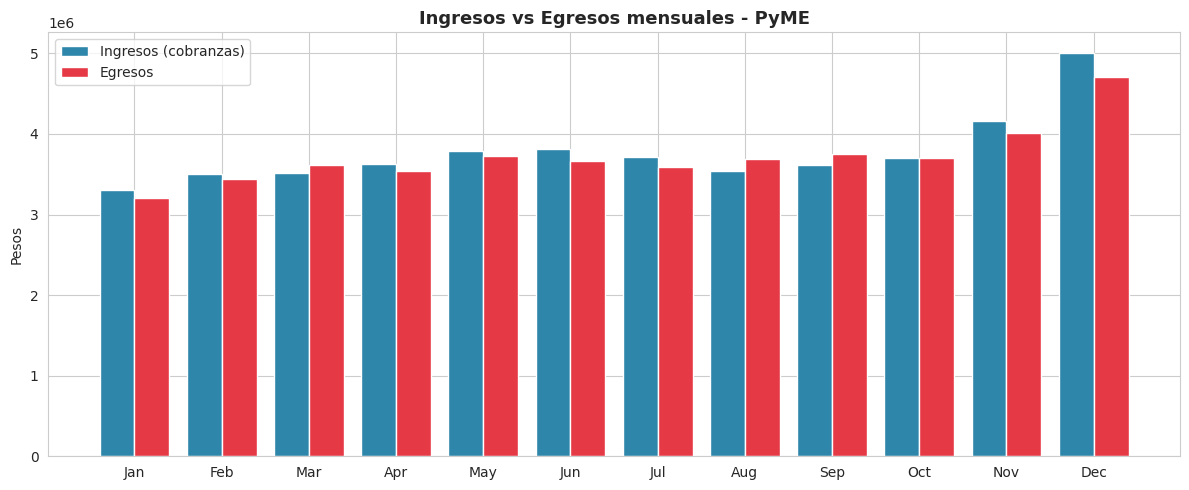

In [16]:
fig, ax = plt.subplots(figsize=(12,5))
x = np.arange(len(df_cf))
ancho = 0.4

ax.bar(x - ancho/2, df_cf['ingresos'], width=ancho, label='Ingresos (cobranzas)', color='#2E86AB')
ax.bar(x + ancho/2, df_cf['egresos'], width=ancho, label='Egresos', color='#E63946')
ax.set_xticks(x)
ax.set_xticklabels(df_cf['mes'].dt.strftime('%b'), rotation=0)
ax.set_title('Ingresos vs Egresos mensuales - PyME', fontsize=13, weight='bold')
ax.set_ylabel('Pesos')
ax.legend()
plt.tight_layout()
plt.show()

###Gráfica: Saldo acumulado con alerta

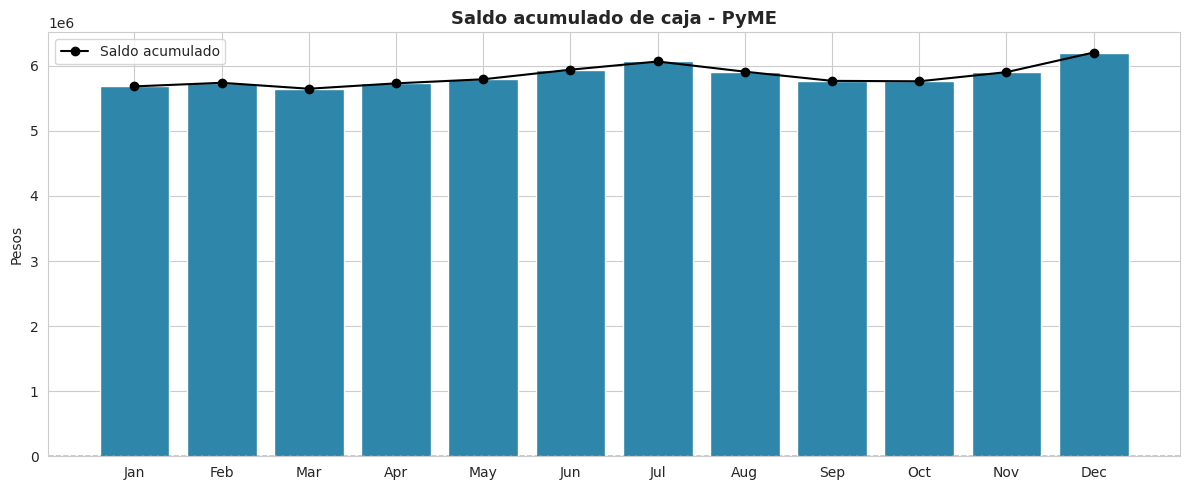

Meses con caja negativa: Ninguno
Caja mínima del año: $5,646,866
Caja máxima del año: $6,203,304


In [36]:
fig, ax = plt.subplots(figsize=(12,5))

colores = ['#E63946' if v < 0 else '#2E86AB' for v in df_cf['saldo_acumulado']]
ax.bar(df_cf['mes'].dt.strftime('%b'), df_cf['saldo_acumulado'], color=colores)
ax.plot(df_cf['mes'].dt.strftime('%b'), df_cf['saldo_acumulado'],
        color='black', marker='o', linewidth=1.5, label='Saldo acumulado')
ax.axhline(0, color='black', linestyle='--', linewidth=1)
ax.set_title('Saldo acumulado de caja - PyME', fontsize=13, weight='bold')
ax.set_ylabel('Pesos')
ax.legend()
plt.tight_layout()
plt.show()

meses_negativos = df_cf[df_cf['saldo_acumulado'] < 0]['mes'].dt.strftime('%b').tolist()
print(f"Meses con caja negativa: {meses_negativos if meses_negativos else 'Ninguno'}")
print(f"Caja mínima del año: ${df_cf['saldo_acumulado'].min():,.0f}")
print(f"Caja máxima del año: ${df_cf['saldo_acumulado'].max():,.0f}")

### Gráfica: Cascada del flujo anual

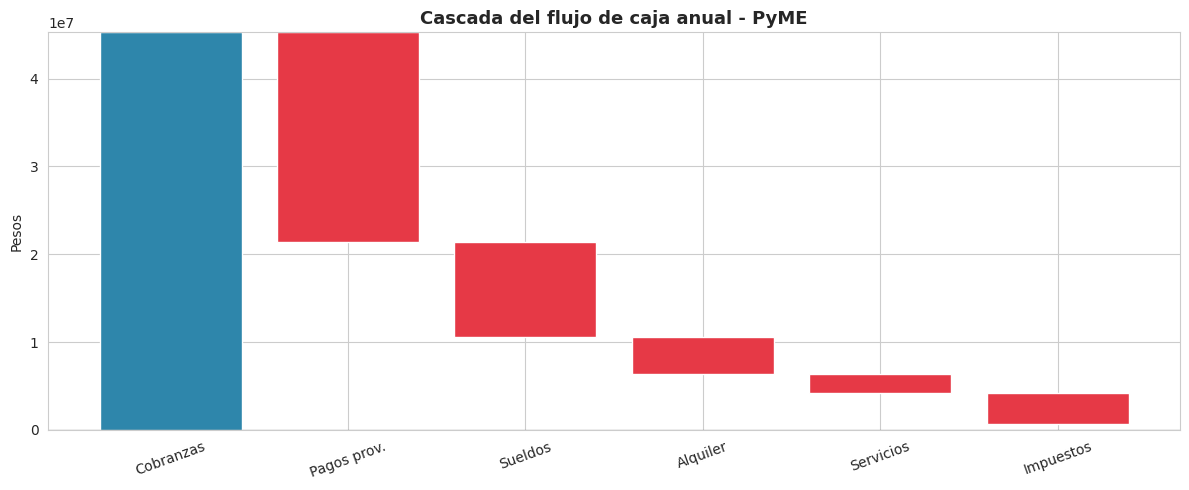

Saldo generado en el año: $620,824
Saldo final de caja: $6,203,304


In [20]:
totales = df_cf[['cobranzas','pagos_proveedores','sueldos','alquiler','servicios','impuestos']].sum()
labels = ['Cobranzas','Pagos prov.','Sueldos','Alquiler','Servicios','Impuestos']
valores = [totales['cobranzas'], -totales['pagos_proveedores'], -totales['sueldos'],
           -totales['alquiler'], -totales['servicios'], -totales['impuestos']]
acum = np.cumsum([0] + valores)

fig, ax = plt.subplots(figsize=(12,5))
for i, (lab, val) in enumerate(zip(labels, valores)):
    color = '#2E86AB' if val > 0 else '#E63946'
    ax.bar(lab, val, bottom=acum[i], color=color)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Cascada del flujo de caja anual - PyME', fontsize=13, weight='bold')
ax.set_ylabel('Pesos')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

print(f"Saldo generado en el año: ${df_cf['saldo_mes'].sum():,.0f}")
print(f"Saldo final de caja: ${df_cf['saldo_acumulado'].iloc[-1]:,.0f}")

###Gráfica: Heatmap de saldos mensuales

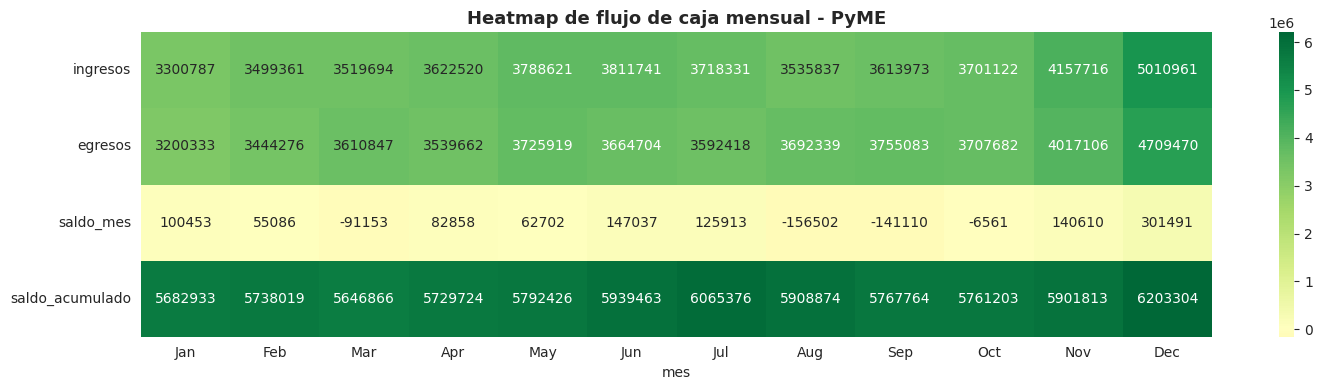

In [37]:
pivot = df_cf.set_index(df_cf['mes'].dt.strftime('%b'))[['ingresos','egresos','saldo_mes','saldo_acumulado']]

fig, ax = plt.subplots(figsize=(15,4))
sns.heatmap(pivot.T, annot=True, fmt='.0f', cmap='RdYlGn', center=0, ax=ax)
ax.set_title('Heatmap de flujo de caja mensual - PyME', fontsize=13, weight='bold')
plt.tight_layout()
plt.show()

---
## Simulación de escenarios: ¿cuándo se rompe la caja?

En vez de asumir una catástrofe, vamos a **tensionar el modelo gradualmente**.

Escenario: los clientes empiezan a pagar más tarde (suba del DSO). ¿A partir de qué punto la PyME entra en zona roja?

In [17]:
def flujo_con_mora(mora_pct):
    """mora_pct: % de caída en cobranzas por atraso de clientes (0 a 40)."""
    cobranzas_ajustadas = df_cf['cobranzas'] * (1 - mora_pct/100)
    saldo_mes = cobranzas_ajustadas - df_cf['egresos']
    return caja_inicial + saldo_mes.cumsum()

escenarios = [0, 10, 20, 30, 40]
resultados = {}

for m in escenarios:
    saldo = flujo_con_mora(m)
    resultados[m] = {
        'caja_minima': saldo.min(),
        'meses_negativos': (saldo < 0).sum(),
        'caja_final': saldo.iloc[-1]
    }

df_esc = pd.DataFrame(resultados).T.round(0)
df_esc.index.name = 'mora_%'
df_esc

,caja_minima,meses_negativos,caja_final
mora_%,,,
0,"5,646,866.00",0.00,"6,203,304.00"
10,"1,675,238.00",0.00,"1,675,238.00"
20,"-2,852,829.00",4.00,"-2,852,829.00"
30,"-7,380,895.00",7.00,"-7,380,895.00"
40,"-11,908,961.00",8.00,"-11,908,961.00"


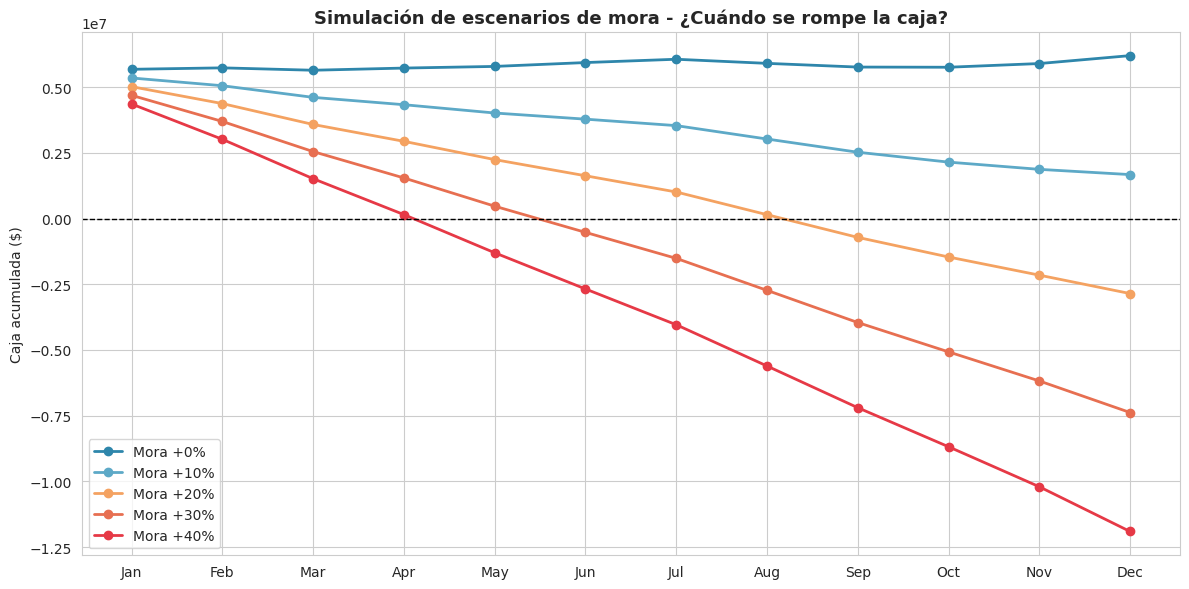

Resumen de escenarios:
          caja_minima  meses_negativos     caja_final
mora_%                                               
0        5,646,866.00             0.00   6,203,304.00
10       1,675,238.00             0.00   1,675,238.00
20      -2,852,829.00             4.00  -2,852,829.00
30      -7,380,895.00             7.00  -7,380,895.00
40     -11,908,961.00             8.00 -11,908,961.00


In [18]:
fig, ax = plt.subplots(figsize=(12,6))
colores = ['#2E86AB', '#5DA9C7', '#F4A261', '#E76F51', '#E63946']

for m, color in zip(escenarios, colores):
    ax.plot(df_cf['mes'].dt.strftime('%b'), flujo_con_mora(m),
            marker='o', label=f'Mora +{m}%', color=color, linewidth=2)

ax.axhline(0, color='black', linestyle='--', linewidth=1)
ax.set_title('Simulación de escenarios de mora - ¿Cuándo se rompe la caja?',
             fontsize=13, weight='bold')
ax.set_ylabel('Caja acumulada ($)')
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

print("Resumen de escenarios:")
print(df_esc)


**Para pensar:**
1. ¿En qué nivel de mora la caja cruza cero?
2. ¿Cuántos meses aguanta la PyME sin cambiar nada?
3. ¿Qué acción de proceso reduciría más el impacto: bajar DSO o subir DPO?

---
## Semáforo de salud financiera

Un indicador visual simple para el dueño: **¿cuántos meses de caja tengo si las cosas siguen así?**

| Runway | Color | Interpretación |
|--------|-------|----------------|
| > 6 meses | 🟢 Verde | Holgura. Puede invertir. |
| 3–6 meses | 🟡 Amarillo | Atención. Revisar procesos. |
| 1–3 meses | 🟠 Naranja | Tensión. Actuar ya. |
| < 1 mes | 🔴 Rojo | Emergencia. Riesgo de cesación de pagos. |

/tmp/ipykernel_2944/3443978255.py:26: UserWarning: Glyph 128992 (\N{LARGE ORANGE CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128992 (\N{LARGE ORANGE CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


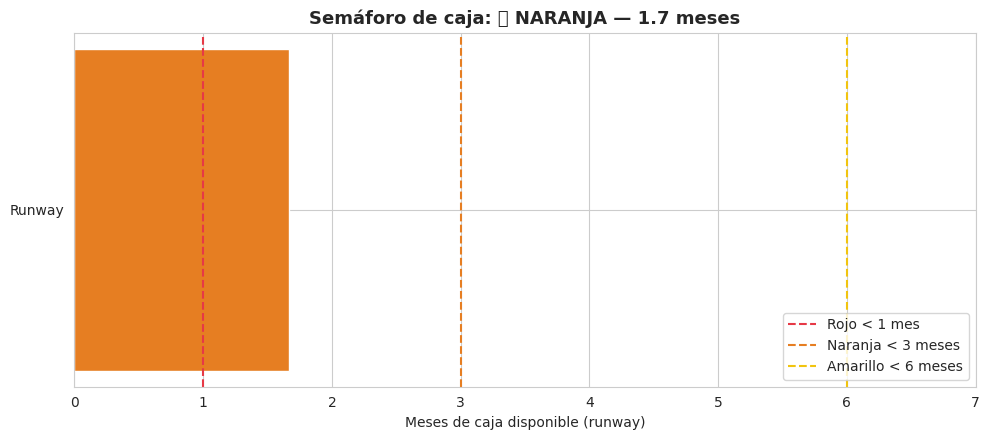

Caja actual: $6,203,304
Egreso mensual promedio: $3,721,653
Runway: 1.7 meses
Estado: 🟠 NARANJA


In [19]:
def semaforo(caja_actual, egreso_mensual):
    runway = caja_actual / egreso_mensual if egreso_mensual > 0 else 0
    if runway > 6:
        return '🟢 VERDE', runway, '#2ECC71'
    elif runway > 3:
        return '🟡 AMARILLO', runway, '#F1C40F'
    elif runway > 1:
        return '🟠 NARANJA', runway, '#E67E22'
    else:
        return '🔴 ROJO', runway, '#E63946'

egreso_prom = df_cf['egresos'].mean()
caja_actual = df_cf['saldo_acumulado'].iloc[-1]
estado, runway, color = semaforo(caja_actual, egreso_prom)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(['Runway'], [runway], color=color, height=0.5)
ax.axvline(1, color='#E63946', linestyle='--', linewidth=1.5, label='Rojo < 1 mes')
ax.axvline(3, color='#E67E22', linestyle='--', linewidth=1.5, label='Naranja < 3 meses')
ax.axvline(6, color='#F1C40F', linestyle='--', linewidth=1.5, label='Amarillo < 6 meses')
ax.set_xlim(0, max(runway*1.3, 7))
ax.set_xlabel('Meses de caja disponible (runway)')
ax.set_title(f'Semáforo de caja: {estado} — {runway:.1f} meses',
             fontsize=13, weight='bold')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

print(f"Caja actual: ${caja_actual:,.0f}")
print(f"Egreso mensual promedio: ${egreso_prom:,.0f}")
print(f"Runway: {runway:.1f} meses")
print(f"Estado: {estado}")

### 6.1 Semáforo en cada escenario de mora

Ahora combinamos ambas ideas: para cada nivel de mora, ¿qué semáforo le toca?

In [25]:
filas = []
for m in escenarios:
    saldo = flujo_con_mora(m)
    caja_fin = saldo.iloc[-1]
    estado, runway, _ = semaforo(caja_fin, egreso_prom)
    filas.append({
        'Mora %': m,
        'Caja final': f"${caja_fin:,.0f}",
        'Runway (meses)': round(runway, 1),
        'Semáforo': estado
    })

pd.DataFrame(filas)

,Mora %,Caja final,Runway (meses),Semáforo
0,0,"$6,203,304",1.70,🟠 NARANJA
1,10,"$1,675,238",0.50,🔴 ROJO
2,20,"$-2,852,829",-0.80,🔴 ROJO
3,30,"$-7,380,895",-2.00,🔴 ROJO
4,40,"$-11,908,961",-3.20,🔴 ROJO


---
## Del KPI de proceso al impacto en caja

Cerramos el círculo: **si mejoro el proceso, ¿qué pasa con la caja?**

In [29]:
dso_mejora = dso * 0.85
dpo_mejora = dpo * 0.90
ccc_mejora = dso_mejora - dpo_mejora

caja_mejora = ventas_diarias * ccc_mejora
caja_liberada = caja_necesaria - caja_mejora

print(f"DSO: {dso:.1f} -> {dso_mejora:.1f} días")
print(f"DPO: {dpo:.1f} -> {dpo_mejora:.1f} días")
print(f"CCC: {ccc:.1f} -> {ccc_mejora:.1f} días")
print(f"Caja necesaria: ${caja_necesaria:,.0f} -> ${caja_mejora:,.0f}")
print(f" Caja liberada: ${caja_liberada:,.0f}")

DSO: 34.8 -> 29.6 días
DPO: 27.7 -> 24.9 días
CCC: 7.1 -> 4.7 días
Caja necesaria: $893,810 -> $585,718
 Caja liberada: $308,091


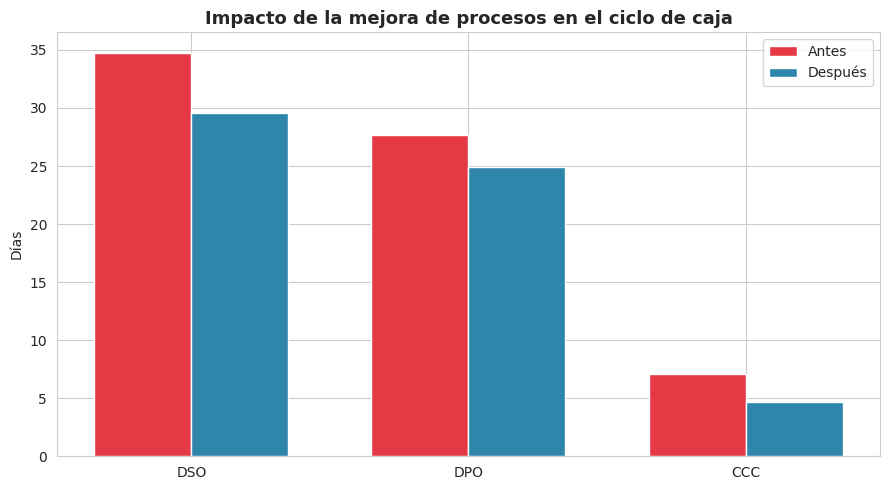

In [30]:
fig, ax = plt.subplots(figsize=(9,5))
categorias = ['DSO', 'DPO', 'CCC']
antes = [dso, dpo, ccc]
despues = [dso_mejora, dpo_mejora, ccc_mejora]
x = np.arange(len(categorias))
ancho = 0.35

ax.bar(x - ancho/2, antes, ancho, label='Antes', color='#E63946')
ax.bar(x + ancho/2, despues, ancho, label='Después', color='#2E86AB')
ax.set_xticks(x)
ax.set_xticklabels(categorias)
ax.set_ylabel('Días')
ax.set_title('Impacto de la mejora de procesos en el ciclo de caja',
             fontsize=13, weight='bold')
ax.legend()
plt.tight_layout()
plt.show()



---


## Otro CASO: Crisis de Crecimiento en una PyME de Servicios (SoftCo)

**Contexto:**
"SoftCo" es una PyME que desarrolla software a medida. Ha ganado 3 contratos grandes con corporativos. Para cumplir, contrató más programadores (incrementando sus egresos fijos inmediatamente).

**El problema:**
Los clientes corporativos pagan a 60 o 90 días, mientras que los salarios de los programadores se pagan todos los meses. A pesar de ser altamente rentable en los papeles, la empresa experimenta un descalce financiero severo que pondrá en riesgo su continuidad operativa.


---



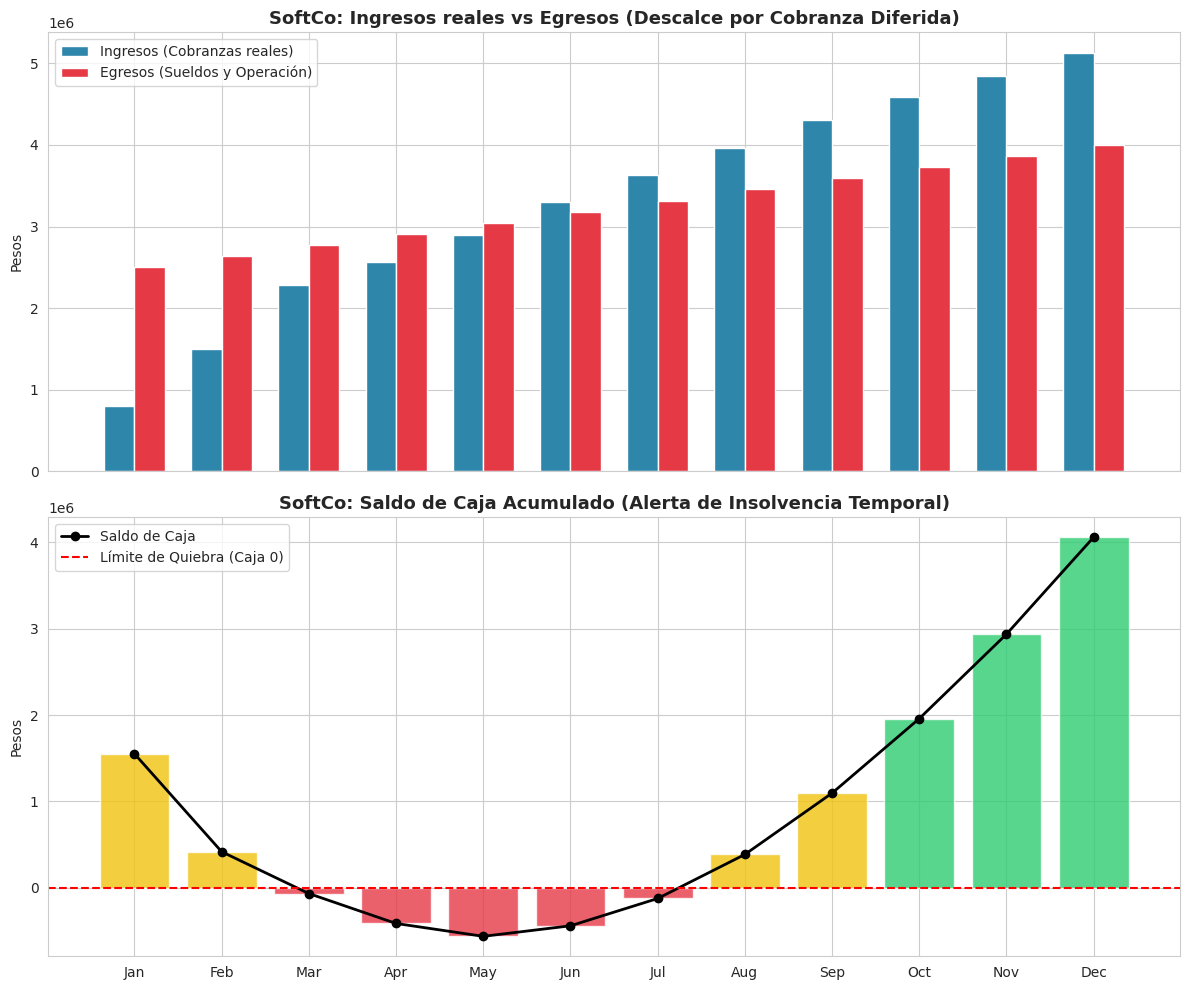

 ALERTA DE CRASH: La empresa se queda sin caja en los meses: March, April, May, June, July
Caja mínima alcanzada: $-563,156.98


In [31]:
# Simulamos 12 meses para SoftCo
np.random.seed(101)
meses_softco = pd.date_range('2025-01-01', periods=12, freq='MS')

# Ventas crecientes (éxito comercial aparente)
ventas_softco = np.linspace(2_000_000, 5_500_000, 12) * np.random.uniform(0.95, 1.05, 12)

# Cobranzas con descalce estructural (clientes grandes pagan tarde)
# Solo cobramos el 30% en el mes de venta, 40% a 30 días y 30% a 60 días
cobranzas_softco = np.zeros(12)
cobranzas_softco[0] = ventas_softco[0] * 0.4  # Cobro inicial parcial
for t in range(1, 12):
    c_mes = ventas_softco[t] * 0.30
    c_mes_1 = ventas_softco[t-1] * 0.40 if t >= 1 else 0
    c_mes_2 = ventas_softco[t-2] * 0.30 if t >= 2 else 0
    cobranzas_softco[t] = c_mes + c_mes_1 + c_mes_2

# Egresos fijos altos y crecientes (incorporación de personal desde el inicio)
egresos_softco = np.linspace(2_500_000, 4_000_000, 12)

# Estructura del flujo de caja de SoftCo
df_softco = pd.DataFrame({
    'mes': meses_softco,
    'ventas': ventas_softco,
    'ingresos': cobranzas_softco,
    'egresos': egresos_softco
})

df_softco['saldo_mes'] = df_softco['ingresos'] - df_softco['egresos']

# Caja inicial moderada (1 mes de egresos promedio)
caja_inicial_softco = egresos_softco.mean()
df_softco['saldo_acumulado'] = caja_inicial_softco + df_softco['saldo_mes'].cumsum()

# Graficamos el resultado para visualizar el descalce y los saldos negativos
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

# Gráfico 1: Ingresos vs Egresos
x_softco = np.arange(12)
ancho_softco = 0.35
ax1.bar(x_softco - ancho_softco/2, df_softco['ingresos'], width=ancho_softco, label='Ingresos (Cobranzas reales)', color='#2E86AB')
ax1.bar(x_softco + ancho_softco/2, df_softco['egresos'], width=ancho_softco, label='Egresos (Sueldos y Operación)', color='#E63946')
ax1.set_title('SoftCo: Ingresos reales vs Egresos (Descalce por Cobranza Diferida)', fontsize=13, weight='bold')
ax1.set_ylabel('Pesos')
ax1.legend()

# Gráfico 2: Saldo Acumulado con Zona de Alerta Roja
colores_softco = ['#E63946' if v < 0 else '#F1C40F' if v < (egresos_softco.mean() * 0.5) else '#2ECC71' for v in df_softco['saldo_acumulado']]
ax2.bar(df_softco['mes'].dt.strftime('%b'), df_softco['saldo_acumulado'], color=colores_softco, alpha=0.8)
ax2.plot(df_softco['mes'].dt.strftime('%b'), df_softco['saldo_acumulado'], color='black', marker='o', linewidth=2, label='Saldo de Caja')
ax2.axhline(0, color='red', linestyle='--', linewidth=1.5, label='Límite de Quiebra (Caja 0)')
ax2.set_title('SoftCo: Saldo de Caja Acumulado (Alerta de Insolvencia Temporal)', fontsize=13, weight='bold')
ax2.set_ylabel('Pesos')
ax2.legend()

plt.tight_layout()
plt.show()

# Consolidado de meses en rojo
meses_rojos = df_softco[df_softco['saldo_acumulado'] < 0]['mes'].dt.strftime('%B').tolist()
print(f" ALERTA DE CRASH: La empresa se queda sin caja en los meses: {', '.join(meses_rojos)}")
print(f"Caja mínima alcanzada: ${df_softco['saldo_acumulado'].min():,.2f}")

### Propuesta de Mejora para SoftCo: Facturación por Hitos con Anticipos

**Estrategia:**
Negociar con los clientes corporativos un esquema de pagos que reduzca el descalce:
* **Antes:** 30% mes actual, 40% a 30 días, 30% a 60 días (descalce promedio de casi 45 días, sumado a retraso inicial).
* **Propuesta (Mejorada):** Cobrar un **50% de anticipo** en el mes de venta (para financiar el costo de desarrollo inmediato) y el **50% restante a 30 días**.

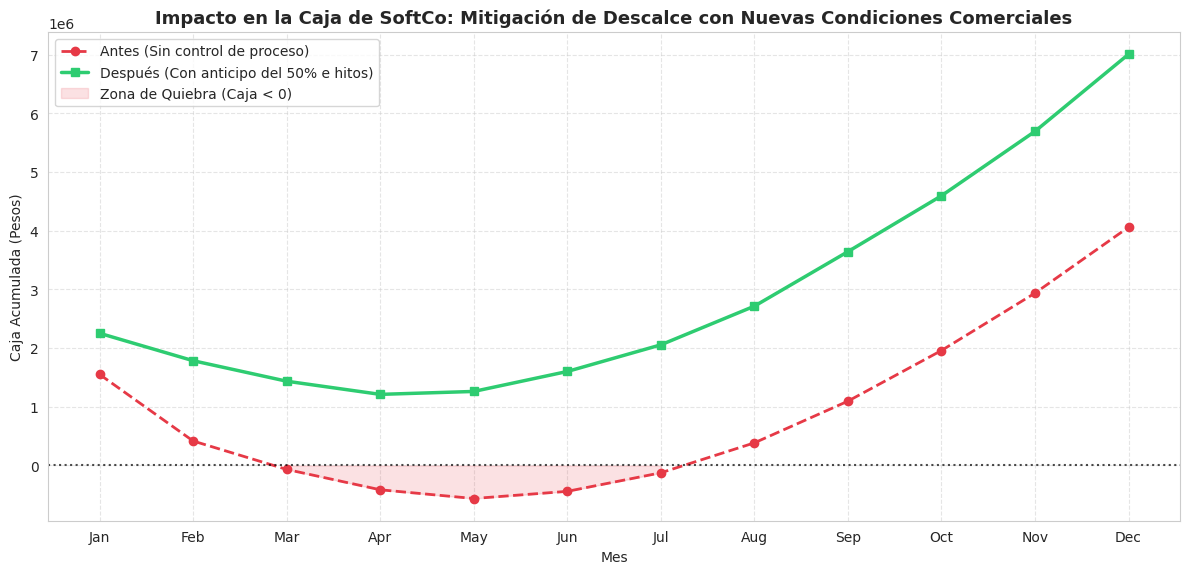

Resultados de la mejora de procesos comercial:
- Meses de caja en saldo negativo 'Antes': 5
- Meses de caja en saldo negativo 'Después': 0
- Caja final proyectada 'Antes': $4,060,721.21
- Caja final proyectada 'Después': $7,007,923.06


In [32]:
# Simulación del escenario de mejora para SoftCo
cobranzas_mejora = np.zeros(12)

# Aplicamos el nuevo esquema: 50% en el mes actual y 50% a 30 días
cobranzas_mejora[0] = ventas_softco[0] * 0.75  # Asumiendo una mejor transición inicial
for t in range(1, 12):
    c_mes = ventas_softco[t] * 0.50
    c_mes_1 = ventas_softco[t-1] * 0.50
    cobranzas_mejora[t] = c_mes + c_mes_1

# Calculamos el nuevo flujo de caja acumulado con la mejora
saldo_mes_mejora = cobranzas_mejora - egresos_softco
saldo_acumulado_mejora = caja_inicial_softco + saldo_mes_mejora.cumsum()

# Graficamos la comparación de saldos de caja (Antes vs Después)
plt.figure(figsize=(12, 6))
plt.plot(df_softco['mes'].dt.strftime('%b'), df_softco['saldo_acumulado'],
         color='#E63946', marker='o', linestyle='--', linewidth=2, label='Antes (Sin control de proceso)')
plt.plot(df_softco['mes'].dt.strftime('%b'), saldo_acumulado_mejora,
         color='#2ECC71', marker='s', linestyle='-', linewidth=2.5, label='Después (Con anticipo del 50% e hitos)')

plt.axhline(0, color='black', linestyle=':', alpha=0.7)
plt.fill_between(df_softco['mes'].dt.strftime('%b'), 0, df_softco['saldo_acumulado'],
                 where=(df_softco['saldo_acumulado'] < 0), color='#E63946', alpha=0.15, label='Zona de Quiebra (Caja < 0)')

plt.title('Impacto en la Caja de SoftCo: Mitigación de Descalce con Nuevas Condiciones Comerciales', fontsize=13, weight='bold')
plt.xlabel('Mes')
plt.ylabel('Caja Acumulada (Pesos)')
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Análisis de resultados del impacto
meses_rojos_despues = np.sum(saldo_acumulado_mejora < 0)
print(f"Resultados de la mejora de procesos comercial:")
print(f"- Meses de caja en saldo negativo 'Antes': {len(meses_rojos)}")
print(f"- Meses de caja en saldo negativo 'Después': {meses_rojos_despues}")
print(f"- Caja final proyectada 'Antes': ${df_softco['saldo_acumulado'].iloc[-1]:,.2f}")
print(f"- Caja final proyectada 'Después': ${saldo_acumulado_mejora[-1]:,.2f}")

---
## Cierre: procesos, finanzas y caja

```
   PROCESO              KPI                MÉTRICA FINANCIERA     IMPACTO EN CAJA
   ───────              ───                ──────────────────     ───────────────
   Order-to-Cash   ──►  DSO / Lead time ──► Capital de trabajo ──► Cobranzas
   Procure-to-Pay  ──►  DPO / TEA desc. ──► Costo financiero   ──► Pagos
   Retrabajo       ──►  % error         ──► Costo operativo    ──► Egresos
   Volumen         ──►  Transacciones   ──► Ingresos           ──► Ingresos
   Proceso total   ──►  CCC             ──► Necesidad de caja  ──► Runway
```

**Mensaje final:**
> En una PyME, la rentabilidad no alcanza.
> **La caja manda.** Los procesos son las palancas que mueven la caja.
> Un analista que sabe medir procesos puede evitar que una PyME rentable se funda.

**Para la próxima clase:**
- Modelado de procesos (BPMN aplicado a PyME)
- Simulación Monte Carlo de cash flow
- Automatización de reportes con Google Sheets + Python

---
## Ejercicio integrador

**Consigna:**
Una PyME gastronómica (restaurante) te pide ayuda. Datos:
- Cobra el 60% en el momento y el 40% a 30 días (eventos y catering).
- Paga a proveedores a 15 días en promedio.
- Ventas mensuales promedio: $3.000.000$ (con estacionalidad).
- Egresos mensuales promedio: $2.700.000$.
- Caja inicial: 1 mes de egresos.

**Tareas:**
1. Armá un DataFrame de flujo de caja para 12 meses con estacionalidad.
2. Calculá DSO, DPO y CCC.
3. Detectá si hay meses con saldo acumulado negativo.
4. Graficá:
   - Ingresos vs egresos
   - Saldo acumulado
   - Cascada anual
   - Semáforo de runway
5. Simulá 3 escenarios de mora (0%, 15%, 30%) y graficá los 3 saldos.
6. Proponé UNA mejora de proceso y mostrá su impacto en la caja (gráfica antes/después).
7. Escribí 3 conclusiones para el dueño (lenguaje no técnico).



---



In [28]:
# Espacio para el ejercicio integrador

ventas_mensuales = 3_000_000
egresos_mensuales = 2_700_000
cobro_inmediato = 0.60
cobro_30d = 0.40
dias_pago_proveedores = 15
caja_inicial_resto = egresos_mensuales * 1.0

# COMPLETAR...